# 01 - Data and setup
**Goal.** Load a free, real dataset (SQuAD v2.0, answerable questions), document it, and create leakage-safe train / calibration / test splits.

**Why SQuAD?** Every question has a gold passage (`rel_pids`) and gold answer strings, so retrieval recall *and* answer-in-context can be measured without an LLM judge. Freely downloadable from GitHub (no login). Optional BEIR corpora (SciFact, NFCorpus) are supported via `load_beir_hf` (needs Hugging Face access, e.g. Colab).

**Outputs:** `csv/dataset_stats.csv`, `csv/split_sizes.csv`, `figures/data_lengths.png`

In [1]:
# ---- Environment setup (works in Colab AND in a local venv / Jupyter) ----
import os, sys, pathlib, subprocess, zipfile
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "faiss-cpu", "sentence-transformers", "python-docx", "psutil"], check=False)
    if not pathlib.Path("adaptive_rag").exists():
        from google.colab import files
        print("Upload rag_adaptive_project.zip (the project archive you downloaded)")
        up = files.upload(); z = [k for k in up if k.endswith(".zip")][0]
        zipfile.ZipFile(z).extractall("."); 
        root = [p for p in pathlib.Path(".").iterdir() if (p / "adaptive_rag").exists()][0]; os.chdir(root)
    try:
        from google.colab import drive; drive.mount("/content/drive")      # results persist on your Drive
        os.environ["RAG_RESULTS_DIR"] = "/content/drive/MyDrive/rag_adaptive_results"
    except Exception as e:
        os.environ["RAG_RESULTS_DIR"] = os.path.abspath("results")
    BACKEND = "st"          # real neural embeddings on Colab (GPU recommended: Runtime > Change runtime type > T4)
else:
    here = pathlib.Path.cwd()
    root = here.parent if here.name == "notebooks" else here
    sys.path.insert(0, str(root)); os.chdir(root)
    os.environ.setdefault("RAG_RESULTS_DIR", str(root / "results_notebooks"))
    BACKEND = "lsa"         # offline CPU baseline (TF-IDF+SVD). Set to "st" if sentence-transformers can download models.
sys.path.insert(0, os.getcwd())
CFG = dict(backend=BACKEND, st_model="sentence-transformers/all-MiniLM-L6-v2", n_queries=int(os.environ.get("RAG_NQ", 10000)), seed=0)
print("backend:", BACKEND, "| results ->", os.environ["RAG_RESULTS_DIR"])


backend: lsa | results -> /home/claude/rag_adaptive_project/results_notebooks


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from adaptive_rag.data import load_squad, corpus_stats, split_by_group
from adaptive_rag.utils import results_dir, env_info, save_json, set_seed
set_seed(0)
corpus, queries = load_squad("train", n_queries=CFG["n_queries"], seed=0)
stats = corpus_stats(corpus, queries); stats.to_csv(results_dir("csv")/"dataset_stats.csv", index=False); display(stats)

,statistic,value
0,n_passages,19035.0000
1,n_articles,442.0000
2,n_queries,10000.0000
3,passage_words_mean,116.5855
4,passage_words_median,107.0000
5,passage_words_p95,209.0000
6,passage_words_max,653.0000
7,query_words_mean,10.0970
8,query_words_median,10.0000
9,rel_passages_per_query_mean,1.0000


In [3]:
queries["split"] = split_by_group(queries).to_numpy()
sp = queries.groupby("split").agg(n_queries=("qid","size"), n_articles=("article_id","nunique")).reset_index()
sp.to_csv(results_dir("csv")/"split_sizes.csv", index=False); display(sp)
# leakage check: no article appears in two splits
assert queries.groupby("article_id")["split"].nunique().max() == 1; print("no article-level leakage between splits")

,split,n_queries,n_articles
0,test,1940,88
1,train,6069,264
2,val,1991,88


no article-level leakage between splits


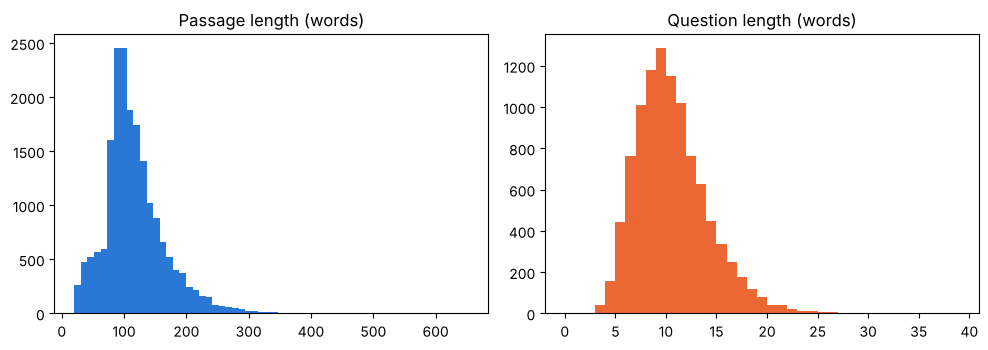

,question,answers
9394,What did Rutherford institute the appointment ...,[a director]
898,Cardinal bishops do not have any powers of gov...,[1962]
2398,In what yer was the Battle of Manzikert fought?,[1071]
5906,"Which Chinese suffix means ""area, district, re...",[qū]
2343,What uncompressed storage option was introduce...,[the Hauppauge 1212 Personal Video Recorder]


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(corpus.text.str.split().str.len(), bins=60, color="#2a78d6"); ax[0].set_title("Passage length (words)")
ax[1].hist(queries.question.str.split().str.len(), bins=range(0, 40), color="#eb6834"); ax[1].set_title("Question length (words)")
plt.tight_layout(); plt.savefig(results_dir("figures")/"data_lengths.png", dpi=300); plt.show()
queries.sample(5, random_state=0)[["question","answers"]]

In [5]:
save_json(env_info(), results_dir("logs")/"environment_notebook01.json"); env_info()

{'timestamp_utc': '2026-10-27T03:52:47.052052+00:00',
 'python': '3.13.17',
 'platform': 'Linux-6.18.44-fc-v165-x86_64-with-glibc2.39',
 'machine': 'x86_64',
 'cpu_count': 2,
 'packages': {'numpy': '2.5.3',
  'pandas': '3.0.5',
  'scipy': '1.18.1',
  'scikit-learn': '1.9.1',
  'matplotlib': '3.11.2',
  'faiss-cpu': '1.15.1',
  'sentence-transformers': None,
  'transformers': None,
  'torch': None,
  'datasets': None,
  'python-docx': '1.2.0'},
 'ram_gb': 8.42,
 'cuda_available': False}